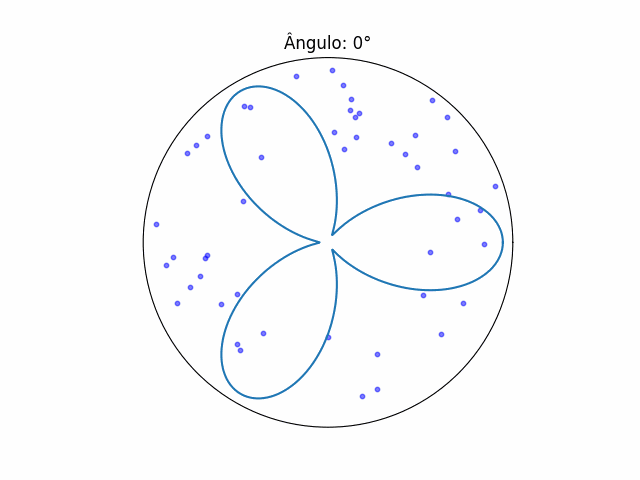

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

def rosacea_gif(raio, num_petalas, variacao_angular, duracao, filename):
    # Configuração inicial
    theta = np.linspace(0, 2 * np.pi, 1000)
    r = raio * np.cos(num_petalas * theta)

    # Criação de pontos scatter iniciais
    num_pontos = 50
    scatter_x = np.random.uniform(0, 2 * np.pi, num_pontos)
    scatter_y = np.random.uniform(0, raio, num_pontos)

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

    # Função de atualização para a animação
    def update(frame):
        ax.clear()
        ax.set_title(f"Ângulo: {frame * variacao_angular}°")
        ax.set_rticks([])  # Remove os ticks radiais
        ax.set_xticks([])  # Remove os ticks angulares
        ax.set_yticklabels([])  # Remove os rótulos radiais
        ax.set_xticklabels([])  # Remove os rótulos angulares

        # Rotaciona a rosácea
        ax.plot(theta + np.deg2rad(frame * variacao_angular), r)

        # Atualiza a posição dos pontos scatter
        scatter_x_variation = scatter_x + np.random.uniform(-0.1, 0.1, num_pontos)
        scatter_y_variation = scatter_y + np.random.uniform(-0.05, 0.05, num_pontos)

        # Adiciona os pontos scatter
        ax.scatter(scatter_x_variation, scatter_y_variation, color='blue', s=10, alpha=0.5)

    # Configuração da animação
    frames = int(360 / variacao_angular)
    interval = 1000 * (360 / variacao_angular) / duracao

    anim = FuncAnimation(fig, update, frames=frames, interval=interval)

    # Salva a animação como GIF
    writer = PillowWriter(fps=10)
    anim.save(filename, writer=writer)

    plt.close()

# Parâmetros de entrada
raio = 1
num_petalas = 3
variacao_angular = 10  # graus por segundo
duracao = 36  # segundos (tempo para uma volta completa)
filename = 'rosacea.gif'

# Geração do GIF
rosacea_gif(raio, num_petalas, variacao_angular, duracao, filename)

from IPython.display import Image
Image(filename=filename)
